<a href="https://colab.research.google.com/github/vishwa24816/Value-at-risk-and-expected-shortfall-/blob/main/Var%20and%20ES.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import numpy as np, pandas as pd, yfinance as yf
import matplotlib.pyplot as plt
from scipy import stats

In [12]:
TICKER, START, END = "RELIANCE.NS", "2018-01-01", "2026-11-01"
CL, WINDOW, N_SIMS = 0.99, 250, 100_000
df = yf.download(TICKER, start=START, end=END, interval="1d", auto_adjust=True, progress=False)
prices = df["Close"].squeeze().dropna()
prices.tail()

,RELIANCE.NS
Date,
2026-10-26,"1,201.80"
2026-10-27,"1,196.20"
2026-10-28,"1,158.00"
2026-10-29,"1,167.40"
2026-10-30,"1,164.90"


In [13]:
returns = np.log(prices / prices.shift(1)).dropna()
print(returns.describe())
print("Skew:", stats.skew(returns), "| Excess kurtosis:", stats.kurtosis(returns))

count   2,180.00
mean        0.00
std         0.02
min        -0.14
25%        -0.01
50%         0.00
75%         0.01
max         0.14
Name: RELIANCE.NS, dtype: float64
Skew: 0.061760136146641144 | Excess kurtosis: 9.075063087685306


In [14]:
def hist_var_es(r, cl=CL):
    var = -np.percentile(r, (1 - cl) * 100)
    es = -r[r <= -var].mean()
    return var, es

h_var, h_es = hist_var_es(returns.values)
print(f"Historical  VaR: {h_var:.4%} | ES: {h_es:.4%}")

Historical  VaR: 4.0673% | ES: 6.5309%


In [15]:
def param_var_es(r, cl=CL):
    mu, sigma = np.mean(r), np.std(r, ddof=1)
    z = stats.norm.ppf(1 - cl)
    var = -(mu + z * sigma)
    es = -(mu - sigma * stats.norm.pdf(z) / (1 - cl))
    return var, es

p_var, p_es = param_var_es(returns.values)
print(f"Var-Covar   VaR: {p_var:.4%} | ES: {p_es:.4%}")

Var-Covar   VaR: 3.9690% | ES: 4.5543%


In [16]:
def mc_var_es(r, cl=CL, n=N_SIMS, seed=42):
    rng = np.random.default_rng(seed)
    mu, sigma = np.mean(r), np.std(r, ddof=1)
    sims = rng.normal(mu, sigma, n)
    var = -np.percentile(sims, (1 - cl) * 100)
    es = -sims[sims <= -var].mean()
    return var, es

m_var, m_es = mc_var_es(returns.values)
print(f"Monte Carlo VaR: {m_var:.4%} | ES: {m_es:.4%}")

Monte Carlo VaR: 3.9987% | ES: 4.5928%


In [17]:
r = returns.values
rows = []
for t in range(WINDOW, len(r)):
    w = r[t - WINDOW:t]
    rows.append({
        "date": returns.index[t], "ret": r[t],
        "Historical": hist_var_es(w)[0],
        "VarCovar": param_var_es(w)[0],
        "MonteCarlo": mc_var_es(w, n=10_000)[0],
    })
bt = pd.DataFrame(rows).set_index("date")
bt.tail()

,ret,Historical,VarCovar,MonteCarlo
date,,,,
2026-10-26,0.01,0.03,0.03,0.03
2026-10-27,-0.00,0.03,0.03,0.03
2026-10-28,-0.03,0.03,0.03,0.03
2026-10-29,0.01,0.03,0.03,0.03
2026-10-30,-0.00,0.03,0.03,0.03


In [18]:
def kupiec(breaches, n, p):
    x = breaches
    if x == 0:
        lr = -2 * n * np.log(1 - p)
    else:
        ph = x / n
        lr = -2 * (((n - x) * np.log(1 - p) + x * np.log(p)) -
                   ((n - x) * np.log(1 - ph) + x * np.log(ph)))
    return lr, 1 - stats.chi2.cdf(lr, 1)

p = 1 - CL
out = []
for m in ["Historical", "VarCovar", "MonteCarlo"]:
    br = int((bt["ret"] < -bt[m]).sum())
    lr, pv = kupiec(br, len(bt), p)
    out.append({"Method": m, "Breaches": br, "Breach rate": br / len(bt),
                "Expected rate": p, "Kupiec p-value": pv})
results = pd.DataFrame(out).set_index("Method")
results

,Breaches,Breach rate,Expected rate,Kupiec p-value
Method,,,,
Historical,24,0.01,0.01,0.30
VarCovar,30,0.02,0.01,0.02
MonteCarlo,29,0.02,0.01,0.04


In [19]:
results["Gap"] = (results["Breach rate"] - p).abs()
valid = results[results["Kupiec p-value"] > 0.05]
best = (valid if len(valid) else results)["Gap"].idxmin()
print("Best method:", best)

final = pd.DataFrame({
    "VaR": [h_var, p_var, m_var],
    "ES": [h_es, p_es, m_es]
}, index=["Historical", "VarCovar", "MonteCarlo"])
final.style.format("{:.4%}")

Best method: Historical


,VaR,ES
Historical,4.0673%,6.5309%
VarCovar,3.9690%,4.5543%
MonteCarlo,3.9987%,4.5928%


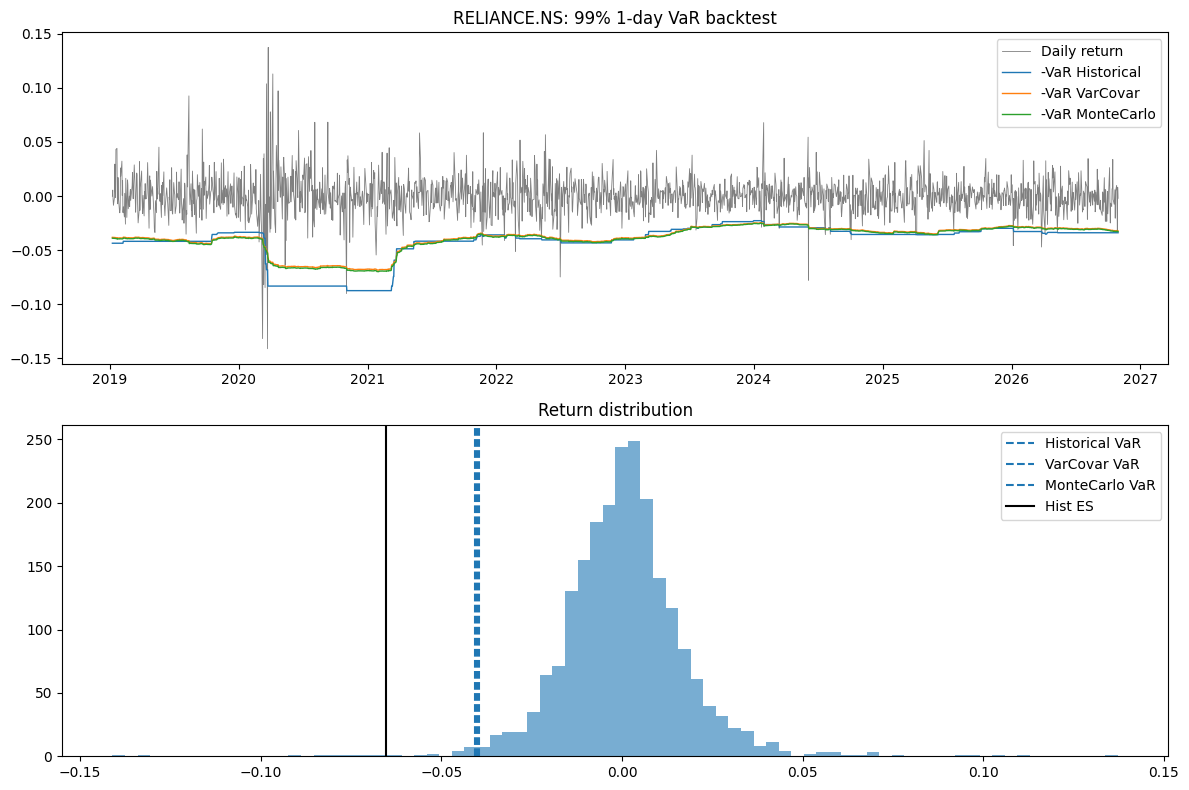

In [20]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8))
ax[0].plot(bt.index, bt["ret"], lw=0.6, color="gray", label="Daily return")
for m in ["Historical", "VarCovar", "MonteCarlo"]:
    ax[0].plot(bt.index, -bt[m], lw=1, label=f"-VaR {m}")
ax[0].legend(); ax[0].set_title(f"{TICKER}: {CL:.0%} 1-day VaR backtest")

ax[1].hist(returns, bins=80, alpha=0.6)
for name, v in zip(final.index, final["VaR"]):
    ax[1].axvline(-v, label=f"{name} VaR", ls="--")
ax[1].axvline(-h_es, color="k", label="Hist ES")
ax[1].legend(); ax[1].set_title("Return distribution")
plt.tight_layout(); plt.show()